# DTM516E – Quiz 1: Ship as a Wave Buoy (SAWB)
Aslı İlhan · İTÜ GDTM

The aim is to estimate the sea state ($H_s$, $T_p$, wave direction $D_p$) from the 6-DoF motions of a ship sailing at 15 kn, using an MLP.
The simulations give motions = f(waves); here I try to learn the inverse, waves = f⁻¹(motions).

Sections follow the quiz tasks:
1. Data preprocessing and preparation
2. ML model implementation
3. Training and hyperparameter tuning
4. Analysis of the results
5. Conclusions and further remarks

## 0. Setup

In [ ]:
# On Colab: uncomment to get the data from Google Drive (project1_data.rar in "My Drive")
# from google.colab import drive; drive.mount('/content/drive')
# !mkdir -p /content/data && unrar x -o+ "/content/drive/MyDrive/project1_data.rar" /content/data/ > /dev/null

In [ ]:
import os, time, itertools
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal, stats
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

os.makedirs("figs", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

device: cpu


## 1. Data preprocessing and preparation
### 1.1 Loading the data
Following the loading notebook that came with the data: `X` is (samples, 6 DoF, time steps), plus `Hs`, `Tp`, `Dir` per sea state.

In [ ]:
CANDIDATES = ["data/project1_data/Data_Project1.npz", "project1_data/Data_Project1.npz",
              "Data_Project1.npz", "/content/data/project1_data/Data_Project1.npz",
              "/content/drive/MyDrive/Data_Project1.npz"]
DATA_PATH = next(p for p in CANDIDATES if os.path.exists(p))

data = np.load(DATA_PATH, allow_pickle=True)
X_raw = data["X"].astype(np.float32)          # (N, 6, T)
Hs, Tp, Dir = data["Hs"], data["Tp"], data["Dir"]

DT = 0.25                                       # time step [s]
FS = 1 / DT                                     # sampling frequency [Hz]
DOF = ["surge", "sway", "heave", "roll", "pitch", "yaw"]
N, n_dof, T = X_raw.shape
print(f"{N} sea states, {n_dof} DoF, {T} steps = {T*DT:.0f} s")
print(f"Hs {Hs.min():.2f}-{Hs.max():.2f} m | Tp {Tp.min():.2f}-{Tp.max():.2f} s | Dir {Dir.min():.1f}-{Dir.max():.1f} deg")
print("any NaN in X:", np.isnan(X_raw).any())

9927 sea states, 6 DoF, 1920 steps = 480 s
Hs 1.00-7.50 m | Tp 6.50-15.50 s | Dir 0.0-360.0 deg
any NaN in X: False


The slides mention 10 000 sea states and 600 s, but the file has 9 927 samples of 1 920 steps (480 s). I assume part of the simulations and the start-up transient were removed.

### 1.2 First look

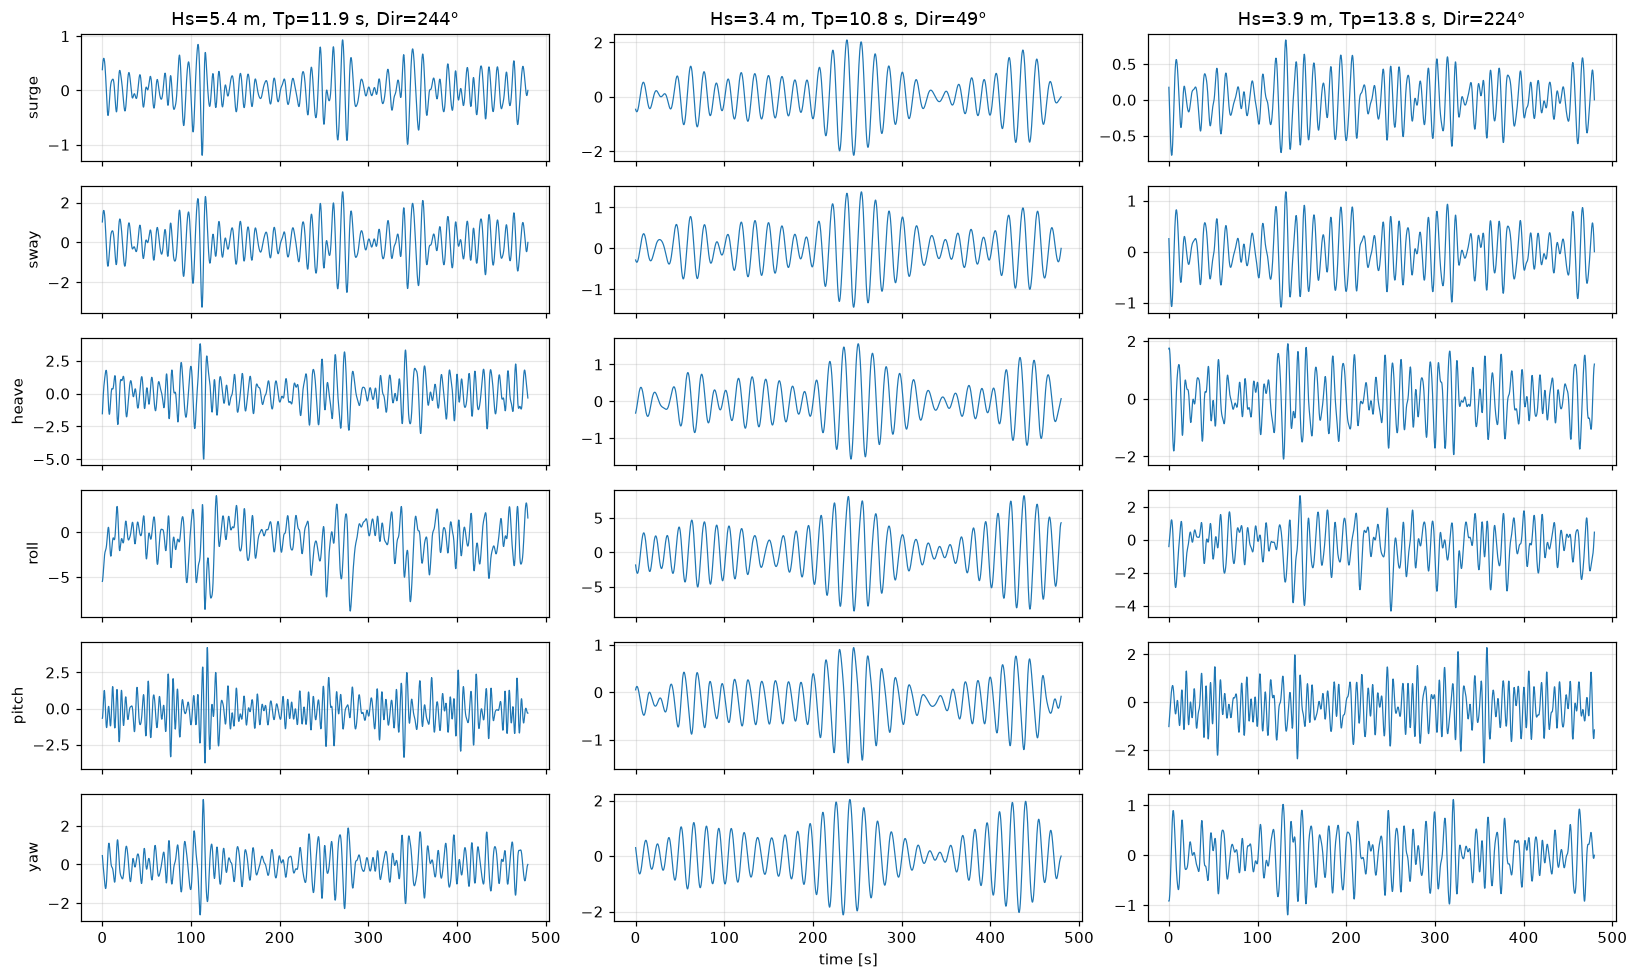

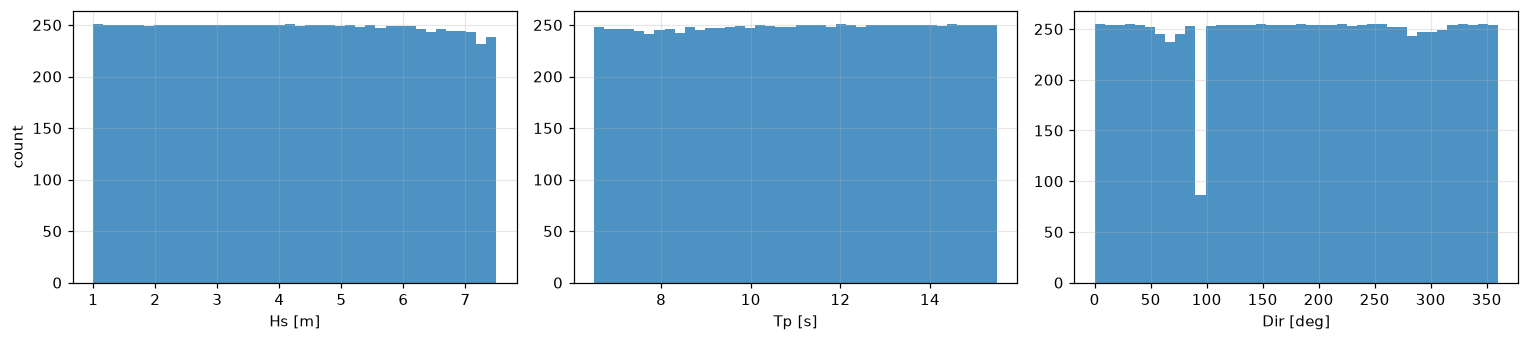

In [ ]:
fig, axes = plt.subplots(6, 3, figsize=(15, 9), sharex=True)
t = np.arange(T) * DT
for c, i in enumerate(np.random.default_rng(1).integers(0, N, 3)):
    axes[0, c].set_title(f"Hs={Hs[i]:.1f} m, Tp={Tp[i]:.1f} s, Dir={Dir[i]:.0f}°")
    for j in range(6):
        axes[j, c].plot(t, X_raw[i, j], lw=0.8)
        axes[j, 0].set_ylabel(DOF[j])
axes[-1, 1].set_xlabel("time [s]")
plt.tight_layout(); plt.savefig("figs/01_samples.png", bbox_inches="tight"); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 3.2))
for ax, v, name in zip(axes, [Hs, Tp, Dir], ["Hs [m]", "Tp [s]", "Dir [deg]"]):
    ax.hist(v, bins=40, color="tab:blue", alpha=0.8); ax.set_xlabel(name)
axes[0].set_ylabel("count")
plt.tight_layout(); plt.savefig("figs/02_targets.png", bbox_inches="tight"); plt.show()

The targets are almost uniform (LHS sampling), except for a clear dip in direction around 90° (beam seas). Most of the missing simulations seem to be there.
I'll keep this in mind when looking at the direction errors.

### 1.3 Feature extraction
6 × 1920 = 11 520 raw values per sample is a lot for an MLP (many weights, and it does not know about time order anyway).
So I summarise each sea state with features, starting from what is used for wave spectra:

- per DoF: mean, std, peak-to-peak, skewness, kurtosis, and from the Welch spectrum the moments $m_0, m_1, m_2, m_4$ (log, because they scale with $H_s^2$), peak frequency, $T_{m01}=m_0/m_1$, $T_z=\sqrt{m_0/m_2}$ → 72 features
- per pair of DoF: normalised co-spectrum and quadrature spectrum → 30 features

Why the pairs: amplitudes alone should not be able to tell port from starboard (or bow from stern) — that should be in the phase between motions, e.g. roll vs sway.

In [ ]:
def extract_features(X, fs=FS):
    N, D, T = X.shape
    feats, names = [], []
    x = X - X.mean(axis=2, keepdims=True)                         # oscillation around the mean

    # statistics
    for name, val in [("mean", X.mean(2)), ("std", x.std(2)), ("p2p", X.max(2) - X.min(2)),
                      ("skew", stats.skew(x, axis=2)), ("kurt", stats.kurtosis(x, axis=2))]:
        feats.append(val); names += [f"{d}_{name}" for d in DOF]

    # spectrum
    f, S = signal.welch(x, fs=fs, nperseg=256, axis=2)
    m = {k: np.trapezoid(f**k * S, f, axis=2) + 1e-12 for k in (0, 1, 2, 4)}
    for k in (0, 1, 2, 4):
        feats.append(np.log(m[k])); names += [f"{d}_logm{k}" for d in DOF]
    feats.append(f[S.argmax(2)]); names += [f"{d}_fp" for d in DOF]
    feats.append(m[0] / m[1]);    names += [f"{d}_Tm01" for d in DOF]
    feats.append(np.sqrt(m[0] / m[2])); names += [f"{d}_Tz" for d in DOF]

    # phase between DoF pairs (co- and quadrature spectrum)
    Xf = np.fft.rfft(x, axis=2)
    power = (np.abs(Xf) ** 2).sum(2)
    for i, j in itertools.combinations(range(D), 2):
        cross = (Xf[:, i] * np.conj(Xf[:, j])).sum(1) / np.sqrt(power[:, i] * power[:, j] + 1e-12)
        feats += [cross.real[:, None], cross.imag[:, None]]
        names += [f"{DOF[i]}-{DOF[j]}_co", f"{DOF[i]}-{DOF[j]}_quad"]

    F = np.concatenate([a if a.ndim == 2 else a[:, None] for a in feats], axis=1).astype(np.float32)
    return F, names

t0 = time.time()
F, feat_names = extract_features(X_raw)
print(f"features: {F.shape}  ({time.time()-t0:.1f} s)")
print("all finite:", np.isfinite(F).all())

features: (9927, 102)  (4.1 s)
all finite: False


First run: some features were not finite. Checking which rows/columns:

In [ ]:
bad = ~np.isfinite(F).all(axis=1)
bad_cols = np.array(feat_names)[~np.isfinite(F[bad]).all(axis=0)]
print(f"{bad.sum()} sea states, features: {list(bad_cols)}")
print("their directions:", np.round(Dir[bad], 1))

16 sea states, features: [np.str_('surge_skew'), np.str_('sway_skew'), np.str_('yaw_skew'), np.str_('surge_kurt'), np.str_('sway_kurt'), np.str_('yaw_kurt')]
their directions: [346.2   9.6 350.  355.9  14.2 352.   19.6 359.5   7.1 352.   10.8   1.3
   6.5   4.6 359.5 359.3]


Only skewness/kurtosis of surge, sway and yaw. For these sea states the signal is constant, so the std is zero and skew/kurt are undefined.
Only 16 of 9 927 samples, so I simply remove them.

In [ ]:
F, X_raw = F[~bad], X_raw[~bad]
Hs, Tp, Dir = Hs[~bad], Tp[~bad], Dir[~bad]
N = len(F)
print("dataset after cleaning:", F.shape)

dataset after cleaning: (9911, 102)


Quick check that the features make physical sense:

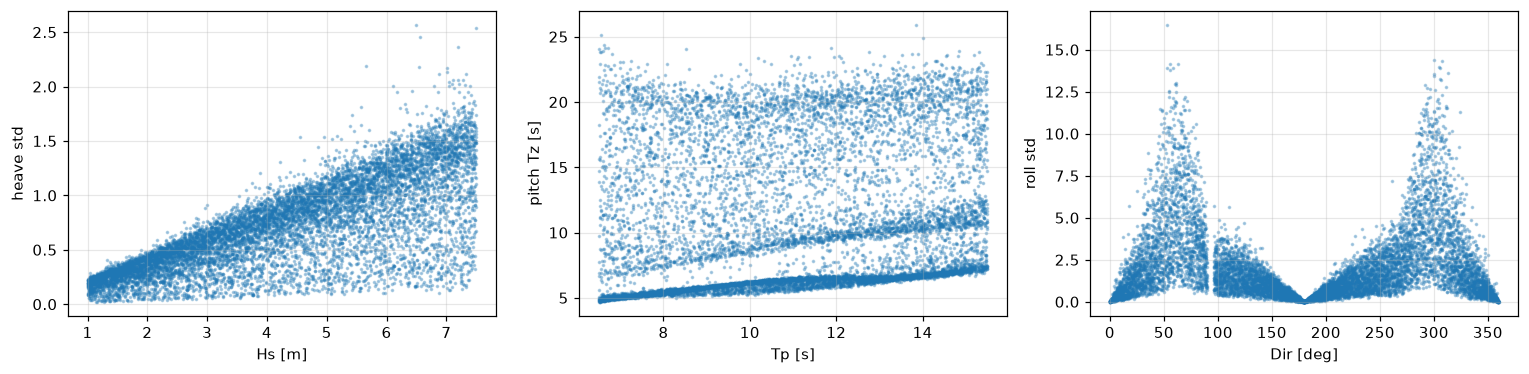

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
k = feat_names.index("heave_std")
axes[0].scatter(Hs, F[:, k], s=2, alpha=0.3); axes[0].set_xlabel("Hs [m]"); axes[0].set_ylabel("heave std")
k = feat_names.index("pitch_Tz")
axes[1].scatter(Tp, F[:, k], s=2, alpha=0.3); axes[1].set_xlabel("Tp [s]"); axes[1].set_ylabel("pitch Tz [s]")
k = feat_names.index("roll_std")
axes[2].scatter(Dir, F[:, k], s=2, alpha=0.3); axes[2].set_xlabel("Dir [deg]"); axes[2].set_ylabel("roll std")
plt.tight_layout(); plt.savefig("figs/03_feature_sanity.png", bbox_inches="tight"); plt.show()

- heave std grows roughly linearly with Hs ✓
- pitch $T_z$ increases with Tp (several bands, probably due to the encounter frequency changing with heading)
- roll is almost zero around 0° and 180° (head/following seas) and largest for oblique waves; the jump near 90° is again the missing simulations.

### 1.4 Target for direction
Training with MSE on the raw angle would treat 359° and 1° as 358° apart. Instead I predict $\sin D_p$ and $\cos D_p$ and get the angle back with atan2.
Outputs: $H_s$, $T_p$, $\sin D_p$, $\cos D_p$.

In [ ]:
rad = np.deg2rad(Dir)
Y = np.stack([Hs, Tp, np.sin(rad), np.cos(rad)], axis=1).astype(np.float32)
print("Y:", Y.shape)

Y: (9911, 4)


### 1.5 Split and normalisation
Random 70 / 15 / 15 split (train / validation / test); each sample is a separate sea state, so there is no overlap between sets.
Standardisation uses mean and std of the **training** set only. The test set is only used once at the end.

In [ ]:
idx = np.random.default_rng(SEED).permutation(N)
n_tr, n_va = int(0.70 * N), int(0.15 * N)
i_tr, i_va, i_te = idx[:n_tr], idx[n_tr:n_tr + n_va], idx[n_tr + n_va:]
print(f"train {len(i_tr)} | val {len(i_va)} | test {len(i_te)}")

x_mu, x_sd = F[i_tr].mean(0), F[i_tr].std(0) + 1e-8
y_mu, y_sd = Y[i_tr].mean(0), Y[i_tr].std(0) + 1e-8
Fn, Yn = (F - x_mu) / x_sd, (Y - y_mu) / y_sd

def to_tensor(i): return torch.tensor(Fn[i]), torch.tensor(Yn[i])
Xtr, Ytr = to_tensor(i_tr); Xva, Yva = to_tensor(i_va); Xte, Yte = to_tensor(i_te)

train 6937 | val 1486 | test 1488


## 2. Model
Fully connected network: 102 inputs → hidden layers with ReLU → 4 linear outputs (regression, so no activation at the end).
Layer sizes and dropout are arguments so I can change them during tuning.

In [ ]:
class MLP(nn.Module):
    def __init__(self, n_in, hidden=(128, 128), n_out=4, dropout=0.0):
        super().__init__()
        layers, prev = [], n_in
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.ReLU()]
            if dropout > 0: layers.append(nn.Dropout(dropout))
            prev = h
        layers.append(nn.Linear(prev, n_out))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

model = MLP(F.shape[1])
print(model)
print("parameters:", sum(p.numel() for p in model.parameters()))

MLP(
  (net): Sequential(
    (0): Linear(in_features=102, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=4, bias=True)
  )
)
parameters: 30212


## 3. Training and hyperparameter tuning
### 3.1 Training loop
MSE loss, Adam, mini-batches. After each epoch I compute the validation loss and stop if it has not improved for `patience` epochs, keeping the best weights.

In [ ]:
def evaluate(model, X, Y):
    model.eval()
    with torch.no_grad():
        return nn.functional.mse_loss(model(X.to(device)), Y.to(device)).item()

def train(hidden=(128, 128), lr=1e-3, batch_size=64, dropout=0.0, weight_decay=0.0,
          max_epochs=200, patience=15, verbose=False):
    torch.manual_seed(SEED)
    model = MLP(Xtr.shape[1], hidden, Ytr.shape[1], dropout).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    loader = DataLoader(TensorDataset(Xtr, Ytr), batch_size=batch_size, shuffle=True)
    hist = {"train": [], "val": []}
    best, best_state, wait = np.inf, None, 0
    for epoch in range(max_epochs):
        model.train(); running = 0.0
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = nn.functional.mse_loss(model(xb), yb)   # forward + loss
            loss.backward()                                # backprop
            opt.step()                                     # update
            running += loss.item() * len(xb)
        hist["train"].append(running / len(Xtr))
        hist["val"].append(evaluate(model, Xva, Yva))
        if hist["val"][-1] < best:
            best, wait = hist["val"][-1], 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience: break
        if verbose and epoch % 10 == 0:
            print(f"epoch {epoch:3d} | train {hist['train'][-1]:.4f} | val {hist['val'][-1]:.4f}")
    model.load_state_dict(best_state)
    return model, hist, best

### 3.2 Sanity check
Before real training: the network should be able to memorise a single batch of 64 samples (debugging checklist from week 3).

In [ ]:
torch.manual_seed(SEED)
m = MLP(Xtr.shape[1]).to(device); opt = torch.optim.Adam(m.parameters(), lr=1e-3)
xb, yb = Xtr[:64].to(device), Ytr[:64].to(device)
for step in range(500):
    opt.zero_grad(); loss = nn.functional.mse_loss(m(xb), yb); loss.backward(); opt.step()
print(f"loss on 64 samples after 500 steps: {loss.item():.5f}")

loss on 64 samples after 500 steps: 0.00000


Loss goes to ~0, so the data pipeline and the loop work.

### 3.3 First model
Starting point: 2 hidden layers × 128, Adam lr = 1e-3, batch 64 (close to the defaults suggested in week 3).

epoch   0 | train 0.1991 | val 0.0499
epoch  10 | train 0.0169 | val 0.0231
epoch  20 | train 0.0141 | val 0.0209
epoch  30 | train 0.0125 | val 0.0205
epoch  40 | train 0.0116 | val 0.0224
best val MSE 0.0197  (2 s, 43 epochs)


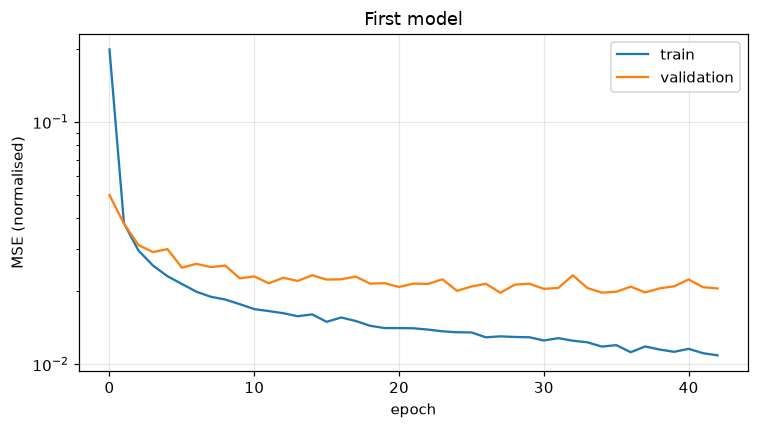

In [ ]:
t0 = time.time()
model_base, hist_base, best_base = train(verbose=True)
print(f"best val MSE {best_base:.4f}  ({time.time()-t0:.0f} s, {len(hist_base['val'])} epochs)")

plt.figure(figsize=(7, 4))
plt.plot(hist_base["train"], label="train"); plt.plot(hist_base["val"], label="validation")
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("MSE (normalised)"); plt.legend()
plt.title("First model")
plt.tight_layout(); plt.savefig("figs/04_learning_curve_base.png", bbox_inches="tight"); plt.show()

Validation MSE ≈ 0.020 after ~40 epochs. The training loss keeps going down while validation flattens, so there is a gap (some variance).
Next: is a different size or learning rate better?

### 3.4 Grid search
Small grid on the two things I expected to matter most: network size (3 options) × learning rate (2 options). Selection on validation loss only.

In [ ]:
grid = {"hidden": [(64, 64), (128, 128), (256, 256, 256)], "lr": [1e-3, 3e-4]}
results = []
for hidden, lr in itertools.product(grid["hidden"], grid["lr"]):
    t0 = time.time()
    m, h, b = train(hidden=hidden, lr=lr)
    results.append({"hidden": hidden, "lr": lr, "val_mse": b, "epochs": len(h["val"]), "model": m, "hist": h})
    print(f"hidden={str(hidden):16s} lr={lr:.0e} -> val MSE {b:.4f}  ({len(h['val'])} ep, {time.time()-t0:.0f} s)")

hidden=(64, 64)         lr=1e-03 -> val MSE 0.0196  (61 ep, 3 s)
hidden=(64, 64)         lr=3e-04 -> val MSE 0.0203  (101 ep, 4 s)
hidden=(128, 128)       lr=1e-03 -> val MSE 0.0197  (43 ep, 2 s)
hidden=(128, 128)       lr=3e-04 -> val MSE 0.0198  (68 ep, 3 s)
hidden=(256, 256, 256)  lr=1e-03 -> val MSE 0.0199  (47 ep, 5 s)
hidden=(256, 256, 256)  lr=3e-04 -> val MSE 0.0200  (43 ep, 5 s)


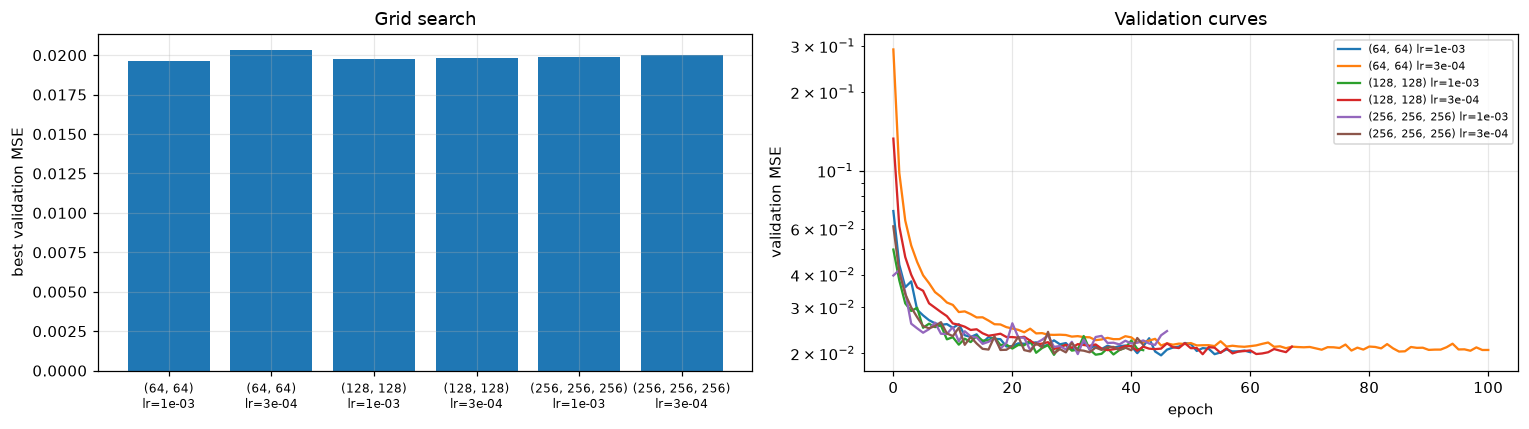

best: (64, 64) lr = 0.001


In [ ]:
labels = [f"{r['hidden']}\nlr={r['lr']:.0e}" for r in results]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(range(len(results)), [r["val_mse"] for r in results], color="tab:blue")
axes[0].set_xticks(range(len(results))); axes[0].set_xticklabels(labels, fontsize=8)
axes[0].set_ylabel("best validation MSE"); axes[0].set_title("Grid search")
for r, lab in zip(results, labels):
    axes[1].plot(r["hist"]["val"], label=lab.replace("\n", " "))
axes[1].set_yscale("log"); axes[1].set_xlabel("epoch"); axes[1].set_ylabel("validation MSE")
axes[1].legend(fontsize=7); axes[1].set_title("Validation curves")
plt.tight_layout(); plt.savefig("figs/05_grid_search.png", bbox_inches="tight"); plt.show()

best = min(results, key=lambda r: r["val_mse"])
print("best:", best["hidden"], "lr =", best["lr"])

Surprising: all six end up around 0.020. A 3-layer network with 256 units is not better than 64-64.
So the network size is not what limits the accuracy — more likely the information in my features. I keep the smallest one (64-64, lr = 1e-3).

### 3.5 Regularisation
Since there was a train/validation gap, I tried two common regularisers on the 64-64 model: dropout 0.1 and L2 weight decay 1e-4.

{'dropout': 0.1} -> val MSE 0.0212
{'weight_decay': 0.0001} -> val MSE 0.0194
final model: {'hidden': (64, 64), 'lr': 0.001, 'val_mse': 0.019429028034210205, 'weight_decay': 0.0001}


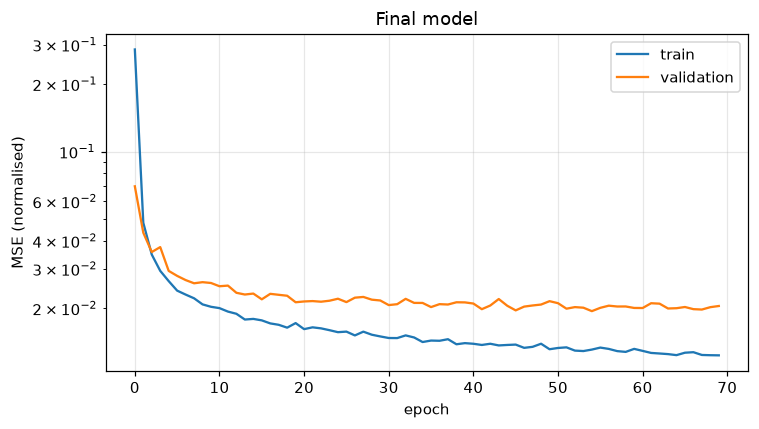

In [ ]:
candidates = [best]
for kw in [{"dropout": 0.1}, {"weight_decay": 1e-4}]:
    m, h, b = train(hidden=best["hidden"], lr=best["lr"], **kw)
    candidates.append({"hidden": best["hidden"], "lr": best["lr"], "val_mse": b, "model": m, "hist": h, **kw})
    print(kw, "-> val MSE", round(b, 4))
final = min(candidates, key=lambda r: r["val_mse"])
model = final["model"]
print("final model:", {k: v for k, v in final.items() if k not in ("model", "hist")})

h = final["hist"]
plt.figure(figsize=(7, 4))
plt.plot(h["train"], label="train"); plt.plot(h["val"], label="validation")
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("MSE (normalised)"); plt.legend()
plt.title("Final model")
plt.tight_layout(); plt.savefig("figs/06_learning_curve_final.png", bbox_inches="tight"); plt.show()

Dropout made it slightly worse, weight decay slightly better. Final model: 64-64, lr = 1e-3, weight decay 1e-4.
The improvement is small, which fits the grid search result.

## 4. Analysis of the results
Now the test set, in physical units. For direction I use the circular error $((\hat D - D + 180) \bmod 360) - 180$, so 358° vs 2° counts as 4°.
To judge the numbers I also compare with a linear model (ridge) on the same features and with just predicting the training mean.

In [ ]:
def predict(model, X):
    model.eval()
    with torch.no_grad():
        yn = model(X.to(device)).cpu().numpy()
    y = yn * y_sd + y_mu
    d = np.rad2deg(np.arctan2(y[:, 2], y[:, 3])) % 360
    return y[:, 0], y[:, 1], d

def ang_err(pred, true):
    return (pred - true + 180) % 360 - 180

def report(name, hs_p, tp_p, d_p, idx):
    e = ang_err(d_p, Dir[idx])
    return {"model": name,
            "Hs MAE": mean_absolute_error(Hs[idx], hs_p), "Hs R2": r2_score(Hs[idx], hs_p),
            "Tp MAE": mean_absolute_error(Tp[idx], tp_p), "Tp R2": r2_score(Tp[idx], tp_p),
            "Dir MAE": np.abs(e).mean(), "Dir <5° [%]": 100 * (np.abs(e) < 5).mean()}

hs_p, tp_p, d_p = predict(model, Xte)
rows = [report("MLP (final)", hs_p, tp_p, d_p, i_te)]

ridge = Ridge(alpha=1.0).fit(Fn[i_tr], Yn[i_tr])
yr = ridge.predict(Fn[i_te]) * y_sd + y_mu
rows.append(report("Linear (ridge)", yr[:, 0], yr[:, 1], np.rad2deg(np.arctan2(yr[:, 2], yr[:, 3])) % 360, i_te))
rows.append(report("Mean predictor", np.full(len(i_te), Hs[i_tr].mean()), np.full(len(i_te), Tp[i_tr].mean()),
                   np.full(len(i_te), 180.0), i_te))

cols = list(rows[0].keys())[1:]
print(f"{'':16s}" + "".join(f"{c:>12s}" for c in cols))
for r in rows:
    print(f"{r['model']:16s}" + "".join(f"{r[c]:12.3f}" for c in cols))
print("\nunits: Hs MAE [m], Tp MAE [s], Dir MAE [deg]")

                      Hs MAE       Hs R2      Tp MAE       Tp R2     Dir MAE Dir <5° [%]
MLP (final)            0.294       0.948       0.261       0.980       1.250      98.320
Linear (ridge)         0.388       0.915       0.487       0.944       8.914      36.828
Mean predictor         1.588      -0.002       2.299      -0.000      88.927       3.091

units: Hs MAE [m], Tp MAE [s], Dir MAE [deg]


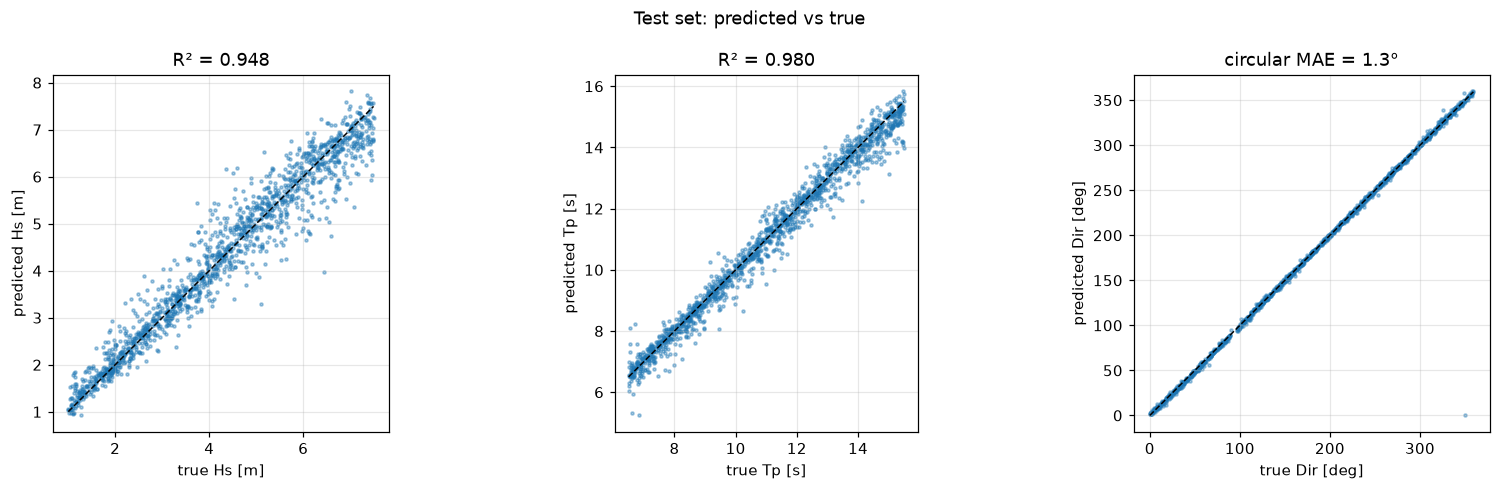

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, true, pred, name, unit in [(axes[0], Hs[i_te], hs_p, "Hs", "m"), (axes[1], Tp[i_te], tp_p, "Tp", "s"),
                                   (axes[2], Dir[i_te], d_p, "Dir", "deg")]:
    ax.scatter(true, pred, s=4, alpha=0.4)
    lo, hi = true.min(), true.max(); ax.plot([lo, hi], [lo, hi], "k--", lw=1)
    ax.set_xlabel(f"true {name} [{unit}]"); ax.set_ylabel(f"predicted {name} [{unit}]"); ax.set_aspect("equal", "box")
axes[0].set_title(f"R² = {r2_score(Hs[i_te], hs_p):.3f}"); axes[1].set_title(f"R² = {r2_score(Tp[i_te], tp_p):.3f}")
axes[2].set_title(f"circular MAE = {np.abs(ang_err(d_p, Dir[i_te])).mean():.1f}°")
plt.suptitle("Test set: predicted vs true"); plt.tight_layout()
plt.savefig("figs/07_pred_vs_true.png", bbox_inches="tight"); plt.show()

The MLP is better than the linear model for all three targets; the biggest difference is in Tp, so the relation between motions and waves is clearly non-linear.
Direction works much better than I expected. Next I look at where the errors are.

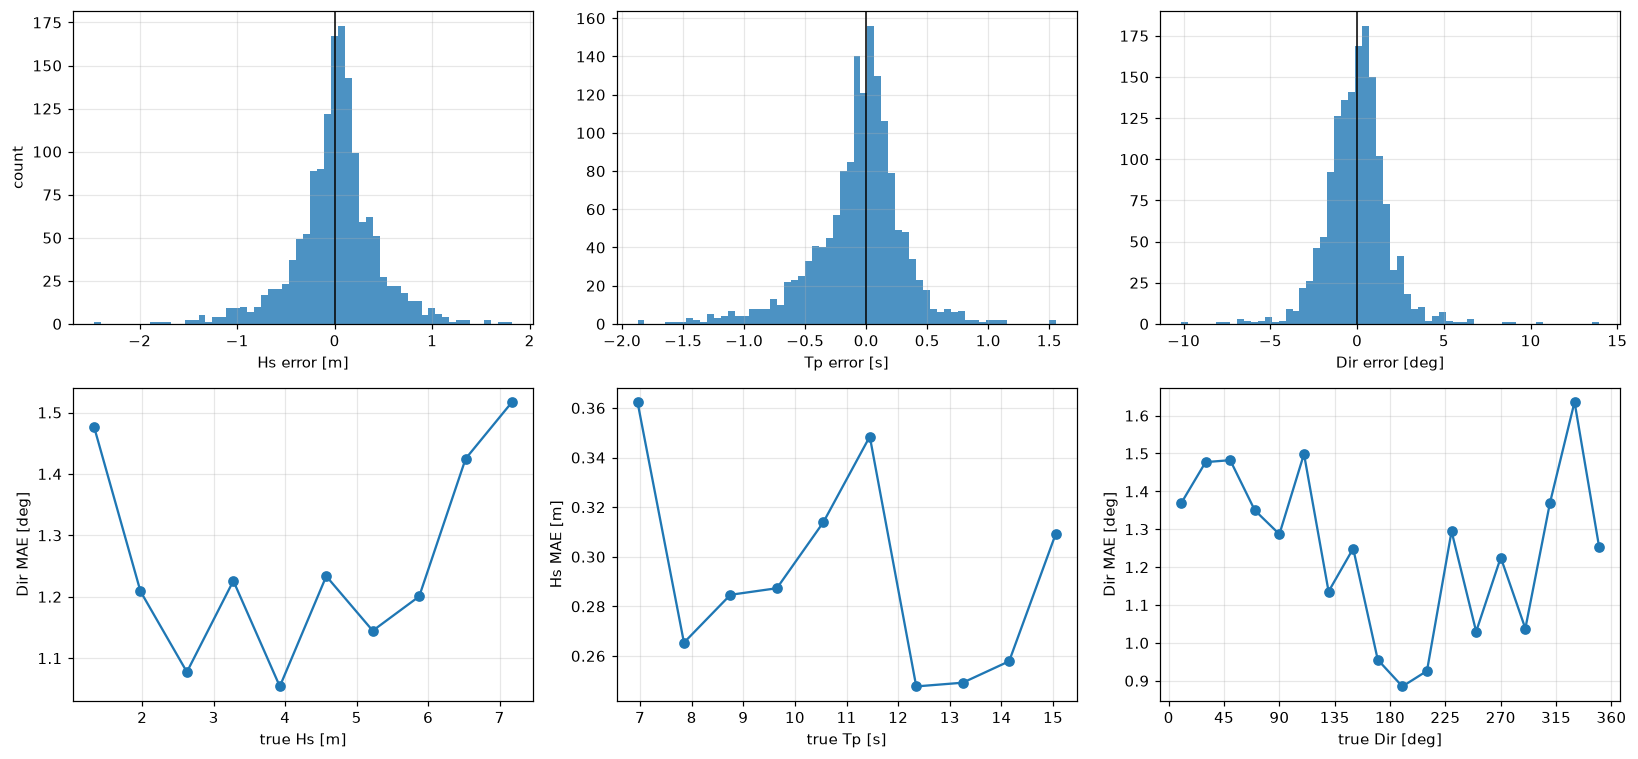

In [ ]:
e_hs, e_tp, e_d = hs_p - Hs[i_te], tp_p - Tp[i_te], ang_err(d_p, Dir[i_te])
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, e, name in zip(axes[0], [e_hs, e_tp, e_d], ["Hs error [m]", "Tp error [s]", "Dir error [deg]"]):
    ax.hist(e, bins=60, color="tab:blue", alpha=0.8); ax.axvline(0, color="k", lw=1); ax.set_xlabel(name)
axes[0, 0].set_ylabel("count")

def binned(ax, x, e, bins, xlabel, ylabel):
    b = np.digitize(x, bins); centres = 0.5 * (bins[1:] + bins[:-1])
    mae = [np.abs(e[b == k]).mean() if (b == k).any() else np.nan for k in range(1, len(bins))]
    ax.plot(centres, mae, "o-"); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)

binned(axes[1, 0], Hs[i_te], e_d, np.linspace(Hs.min(), Hs.max(), 11), "true Hs [m]", "Dir MAE [deg]")
binned(axes[1, 1], Tp[i_te], e_hs, np.linspace(Tp.min(), Tp.max(), 11), "true Tp [s]", "Hs MAE [m]")
binned(axes[1, 2], Dir[i_te], e_d, np.linspace(0, 360, 19), "true Dir [deg]", "Dir MAE [deg]")
axes[1, 2].set_xticks(range(0, 361, 45))
plt.tight_layout(); plt.savefig("figs/08_error_analysis.png", bbox_inches="tight"); plt.show()

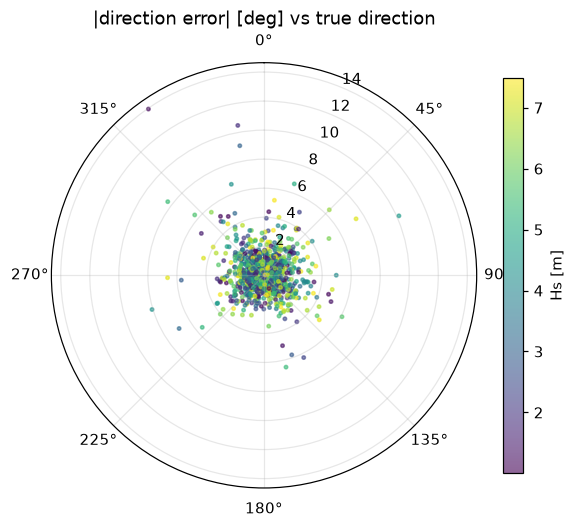

In [ ]:
fig = plt.figure(figsize=(5.5, 5.5)); ax = fig.add_subplot(projection="polar")
ax.set_theta_zero_location("N"); ax.set_theta_direction(-1)
sc = ax.scatter(np.deg2rad(Dir[i_te]), np.abs(e_d), c=Hs[i_te], s=5, cmap="viridis", alpha=0.6)
plt.colorbar(sc, label="Hs [m]", shrink=0.7); ax.set_title("|direction error| [deg] vs true direction")
plt.tight_layout(); plt.savefig("figs/09_direction_polar.png", bbox_inches="tight"); plt.show()

- All error histograms are centred on zero → no systematic over/under-estimation.
- Hs error is largest for the shortest waves (Tp ≈ 7 s). My interpretation: the ship responds less to short waves, so the motions carry less information about them.
- Direction errors are below a few degrees almost everywhere; only a few outliers at oblique headings. I expected the 90° region to be worse because of the missing data, but it is not clearly visible.

## 5. Conclusions and further remarks
- On the test set the MLP gives Hs MAE ≈ 0.29 m (R² 0.95), Tp MAE ≈ 0.26 s (R² 0.98) and direction MAE ≈ 1.3°, better than a linear model on the same features.
- For direction, the phase features between DoF pairs and the sin/cos target were the key choices.
- Changing the network size or learning rate made almost no difference, and regularisation helped only a little → the hand-crafted features are the limit, not the network.
- Limitations: one ship at one speed (15 kn), long-crested waves, simulated data only.
- Next steps: let the network learn its own features from the raw time series with a 1D CNN (Project 1); add speed/loading as inputs; test on measured motions.

In [ ]:
near0, near180 = np.abs(ang_err(Dir, 0)) < 20, np.abs(ang_err(Dir, 180)) < 20
k = feat_names.index("pitch_Tz")
print("pitch Tz near 0°:", F[near0, k].mean().round(1), "s | near 180°:", F[near180, k].mean().round(1), "s")

pitch Tz near 0°: 20.8 s | near 180°: 6.2 s
